In [1]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
import matplotlib.pyplot as plt
import numpy as np

In [7]:
path = "caltech-101"
train = keras.utils.image_dataset_from_directory(
    path,validation_split=0.2,subset="training",
    seed=123,image_size=(224,224),batch_size=32
)
test = keras.utils.image_dataset_from_directory(
    path,validation_split=0.2,subset="validation",
    seed=123,image_size=(224,224),batch_size=32
)

classes = train.class_names

Found 9144 files belonging to 102 classes.
Using 7316 files for training.
Found 9144 files belonging to 102 classes.
Using 1828 files for validation.


In [8]:
base = keras.applications.VGG16(
    weights=None,
    include_top=False,
    input_shape=(224,224,3)
)

base.load_weights("vgg16_weights_tf_dim_ordering_tf_kernels_notop.h5")

base.trainable=False

In [9]:
model = keras.Sequential([
    layers.Input(shape=(224,224,3)),
    layers.Lambda(keras.applications.vgg16.preprocess_input),
    base,
    layers.GlobalAveragePooling2D(),
    layers.Dense(128,activation="relu"),
    layers.Dense(len(classes), activation="softmax")
])

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [10]:
history = model.fit(
    train,
    epochs=5,
    validation_data=test
)


Epoch 1/5
229/229 ━━━━━━━━━━━━━━━━━━━━ 615s 3s/step - accuracy: 0.5837 - loss: 2.1144 - val_accuracy: 0.7943 - val_loss: 0.8450
Epoch 2/5
229/229 ━━━━━━━━━━━━━━━━━━━━ 627s 3s/step - accuracy: 0.8748 - loss: 0.4662 - val_accuracy: 0.8441 - val_loss: 0.6123
Epoch 3/5
229/229 ━━━━━━━━━━━━━━━━━━━━ 619s 3s/step - accuracy: 0.9485 - loss: 0.1972 - val_accuracy: 0.8539 - val_loss: 0.5639
Epoch 4/5
229/229 ━━━━━━━━━━━━━━━━━━━━ 618s 3s/step - accuracy: 0.9825 - loss: 0.0897 - val_accuracy: 0.8665 - val_loss: 0.5397
Epoch 5/5
229/229 ━━━━━━━━━━━━━━━━━━━━ 616s 3s/step - accuracy: 0.9917 - loss: 0.0437 - val_accuracy: 0.8736 - val_loss: 0.5164


In [12]:
loss,accuracy = model.evaluate(test)
print("Loss:", loss)
print("Accuracy:", accuracy*100)

58/58 ━━━━━━━━━━━━━━━━━━━━ 213s 4s/step - accuracy: 0.8736 - loss: 0.5164
Loss: 0.5164042115211487
Accuracy: 87.36323714256287


1/1 ━━━━━━━━━━━━━━━━━━━━ 4s 4s/step


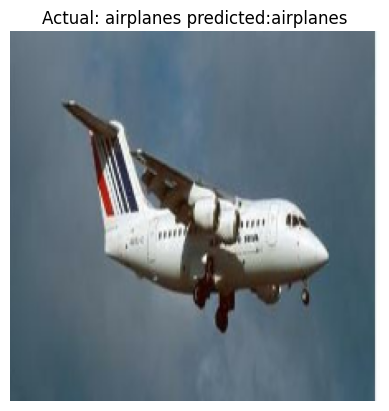

In [17]:
images,labels = next(iter(test))
predictions = model.predict(images)

for i in range(5):
    plt.imshow(images[i].numpy().astype("uint8"))
    plt.title("Actual: "+classes[labels[i]]+ " predicted:"+ classes[np.argmax(predictions[i])])
    plt.axis("off")

plt.show()    

In [19]:
base.trainable = True

for layer in base.layers[:-4]:
    layer.trainable = False

model.compile(
    optimizer=keras.optimizers.Adam(0.00001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.fit(train, validation_data=test, epochs=3)

Epoch 1/3
229/229 ━━━━━━━━━━━━━━━━━━━━ 707s 3s/step - accuracy: 0.9963 - loss: 0.0249 - val_accuracy: 0.8857 - val_loss: 0.5665
Epoch 2/3
229/229 ━━━━━━━━━━━━━━━━━━━━ 738s 3s/step - accuracy: 0.9984 - loss: 0.0148 - val_accuracy: 0.8862 - val_loss: 0.5967
Epoch 3/3
229/229 ━━━━━━━━━━━━━━━━━━━━ 741s 3s/step - accuracy: 0.9989 - loss: 0.0076 - val_accuracy: 0.8900 - val_loss: 0.5883


In [21]:
loss, accuracy = model.evaluate(test)

print("Final Loss:", loss)
print("Final Accuracy:", accuracy * 100)

58/58 ━━━━━━━━━━━━━━━━━━━━ 126s 2s/step - accuracy: 0.8900 - loss: 0.5883
Final Loss: 0.5882577896118164
Final Accuracy: 89.00437355041504


1/1 ━━━━━━━━━━━━━━━━━━━━ 3s 3s/step


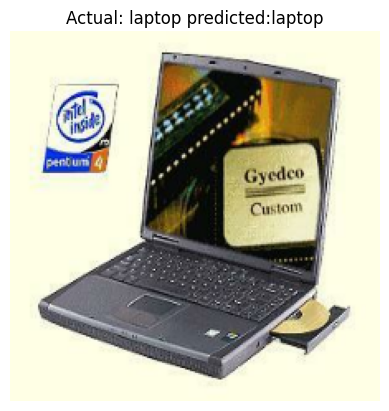

In [22]:
images,labels = next(iter(test))
predictions = model.predict(images)

for i in range(5):
    plt.imshow(images[i].numpy().astype("uint8"))
    plt.title("Actual: "+classes[labels[i]]+ " predicted:"+ classes[np.argmax(predictions[i])])
    plt.axis("off")

plt.show()    